<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/06-SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Máquinas de soporte vectorial
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; Periodo 2026-2
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

A lo largo de este taller, aplicaremos el algoritmo de máquinas de soporte vectorial (SVM) para clasificar un conjunto de datos.

Los paquetes necesarios son:

In [63]:
# Paquetes necesarios
import pandas as pd  # Manejo de datos
import matplotlib.pyplot as plt  # Visualización

from sklearn.preprocessing import StandardScaler  # Estandarización de datos
from sklearn.datasets import make_blobs, make_circles, make_moons # Creación de datos
from sklearn.model_selection import train_test_split # División de datos
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report  # Métrica de evaluación
from sklearn.preprocessing import LabelEncoder # Preprocesamiento de etiquetas

# Algoritmo SVC
from sklearn.svm import SVC

---
## <font color='264CC7'> Clasificación </font>


### <font color='264CC7'> Preprocesamiento de datos </font>

Primero necesitas el conjunto de datos. Usa el conjunto de datos seleccionado en las primeras semanas.

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Carga el conjunto de datos y procésalos:
<ul>
  <li>Muestra algunos datos.</li>
  <li>Muestra una descripción de los datos.</li>
  <li>Define predictores y objetivo, excluyendo información que revele la respuesta.</li>
  <li>Reserva prueba y divide el resto en entrenamiento y validación con semillas registradas; estratifica si se trata de clasificación y los tamaños de clase lo permiten.</li>
  <li>Ajusta imputación, codificación y escalado solo con entrenamiento; transforma validación sin reajustar.</li>
</ul>
</div>

In [64]:
url = 'https://raw.githubusercontent.com/juanfercaicedo/AprendizajeAutomaticoInicial/refs/heads/main/Dataset/futbollStats.csv'
df = pd.read_csv(url)

le = LabelEncoder()

# Tomamos las columnas de interés
columnas_interes = ['partidos_jugados', 'asistencias', 'pases_exitosos', 'pases_clave']
df['posicion_codificada'] = le.fit_transform(df['posicion_base'])
data = df[['jugador', 'posicion_codificada', 'posicion_base', *columnas_interes]]
display(data.head())

,jugador,posicion_codificada,posicion_base,partidos_jugados,asistencias,pases_exitosos,pases_clave
0,Lionel Messi,1,Delantero,1185,428,61479,2972
1,Cristiano Ronaldo,1,Delantero,1343,265,44615,1801
2,Zinedine Zidane,8,Mediocentro Ofensivo,318,78,19225,774
3,Ronaldinho Gaúcho,2,Extremo,685,189,30328,1498
4,Andrés Iniesta,7,Mediocentro,965,192,57022,1607



### <font color='264CC7'> Determinación del mejor kernel </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Determina el mejor kernel para el modelo SVM.
<ul>
  <li>Genera una gráfica que muestre la exactitud (accuracy) de entrenamiento y validación con diferentes kernels.</li>
  <li>Compara también C y, para RBF, gamma sobre las mismas particiones.</li>
  <li>Selecciona la configuración por validación, sin consultar prueba.</li>
</ul>
</div>


,params,accuracy_train,accuracy_val
0,"{'kernel': 'linear', 'C': 0.1}",0.568345,0.510638
1,"{'kernel': 'linear', 'C': 1}",0.755396,0.659574
2,"{'kernel': 'linear', 'C': 10}",0.748201,0.723404
3,"{'kernel': 'poly', 'C': 0.1}",0.294964,0.297872
4,"{'kernel': 'poly', 'C': 1}",0.589928,0.574468
5,"{'kernel': 'poly', 'C': 10}",0.748201,0.617021
6,"{'kernel': 'sigmoid', 'C': 0.1}",0.381295,0.361702
7,"{'kernel': 'sigmoid', 'C': 1}",0.539568,0.510638
8,"{'kernel': 'sigmoid', 'C': 10}",0.517986,0.531915
9,"{'kernel': 'rbf', 'C': 0.1, 'gamma': 0.01}",0.215827,0.212766


Configuración seleccionada en validación: {'kernel': 'linear', 'C': 10}


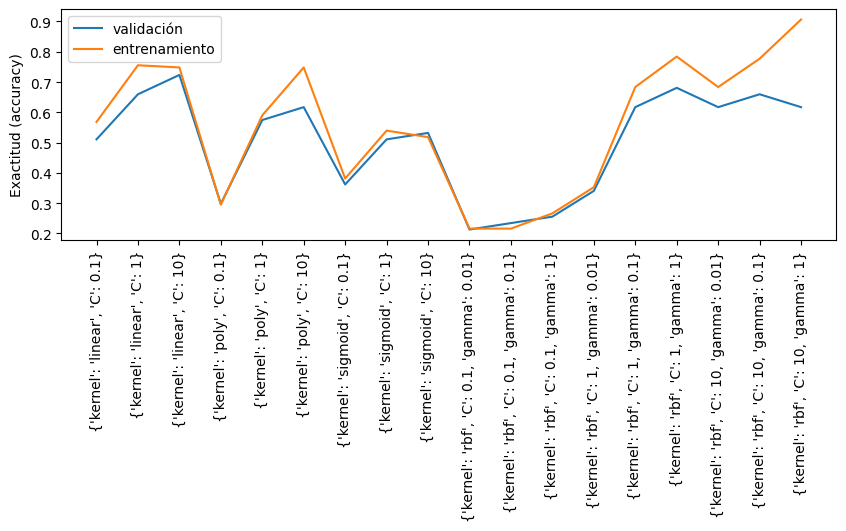

In [65]:
# Reservar prueba antes de ajustar cualquier transformación
X = df[columnas_interes]
y = df['posicion_codificada']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify = y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size = 0.25, random_state=42, stratify = y_train
)

# Ajustar el escalado solo con entrenamiento; transformar validación
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

configurations = [
    {'kernel': kernel, 'C': c}
    for kernel in ['linear', 'poly', 'sigmoid'] for c in [0.1, 1, 10]
] + [
    {'kernel': 'rbf', 'C': c, 'gamma': gamma}
    for c in [0.1, 1, 10] for gamma in [0.01, 0.1, 1]
]
results = []
for params in configurations:
    modelo = SVC(**params)
    modelo.fit(X_train_scaled, y_train)
    results.append({
        'params': params,
        'accuracy_train': accuracy_score(y_train, modelo.predict(X_train_scaled)),
        'accuracy_val': accuracy_score(y_val, modelo.predict(X_val_scaled))
    })

# En caso de empate se conserva la primera configuración evaluada
best_result = max(results, key=lambda row: row['accuracy_val'])
best_params = best_result['params'].copy()
display(pd.DataFrame(results))
print("Configuración seleccionada en validación:", best_params)
plt.figure(figsize=(10, 3))
plt.plot(range(len(results)), [r['accuracy_val'] for r in results], label="validación")
plt.plot(range(len(results)), [r['accuracy_train'] for r in results], label="entrenamiento")
plt.xticks(range(len(results)), [str(r['params']) for r in results], rotation=90)
plt.ylabel("Exactitud (accuracy)")
plt.legend()
plt.show()



### <font color='264CC7'> Entrenamiento del modelo y evaluación </font>


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Entrena el modelo y evalúalo:
<ul>
  <li>Fija kernel e hiperparámetros y reajusta las transformaciones y el modelo con entrenamiento y validación.</li>
  <li>Evalúa una sola vez en la prueba reservada, sin usarla para volver a ajustar.</li>
  <li>Genera una matriz de confusión y muestra las métricas de evaluación.</li>
</ul>
</div>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Compara el modelo con otros algoritmos de clasificación vistos en clases anteriores usando las mismas particiones y métricas de validación; conserva prueba para evaluar una sola vez el modelo final seleccionado.
</div>